# Los productos naturales en la base de datos LOTUS

***

LOTUS es una base de datos abierta creada por el grupo de  ***Quimioinformática y metabolómica computacional*** de la **Universidad Friedich Schiller** en Jena, Alemania; con el propósito de crear un repositorio de moléculas de origen natural disponible para todas las personas que deseasen realizar investigaciones relacionadas con los productos naturales de plantas, hongos y animales, reportando datos de estructuras, nombres científicos, nombres comunes, el organismo en el cual aparece, su taxonomía, propiedades físicas, etcétera. 

> Este repositorio está construido sobre **MongoDB**, es una base de datos ***no relacional*** y está disponible [aquí](https://lotus.naturalproducts.net/)

Asimismo, LOTUS cuenta con una API REST para realizar consultas. Se pueden hacer búsquedas de tres maneras diferentes:

**1. Búsqueda exacta**

---

Se ingresa un código SMILES (una estrategia de abstracción para las estructuras químicas) de la molécula que se quiere buscar por la base de datos. Esta API tiene dos métodos de búsqueda: 1. Usando InChI (Identificador Químico Internacional) como método de coincidencia, y 2. Usando el SMILES como método de coincidencia.


- Caso 1: `https://lotus.naturalproducts.net/api/search/exact-structure?type=inchi&smiles=O=C1OC(C(O)=C1O)CO` 

- Caso 2: 
`https://lotus.naturalproducts.net/api/search/exact-structure?type=smiles&smiles=O=C1OC(C(O)=C1O)CO`  

**2. Búsqueda simple**

---

En este caso, se emplean querys sencillas, como preguntar el LOTUS ID, la clave InChI, el código InChI o el nombre de la molécula:

- `https://lotus.naturalproducts.net/api/search/simple?query=LTS0253154`

**3. Búsqueda por subestructura**

---

Los productos naturales son como una torre de LEGOs: están construidos por bloques representados por un SMILES (un trocito de molécula), y esos bloques son las subestructuras. La API REST de LOTUS permite buscar moléculas por subestructura, ajustando el algoritmo de búsqueda por:
- a) `type`:
    - `default` (Algoritmo de Ullmann): La opción por defecto
    - `df` (Búsqueda en profundidad): Grafos y árboles (*backtracing*)
    - `vf` (Algoritmo de Vento-Foggia)
- b) `max-hits`:
    - Es el máximo de productos naturales a mostrar (tipo `int`)

Ejemplo: `https://lotus.naturalproducts.net/api/search/substructure?type=default&max-hits=100&smiles=O=C1OC(C(O)=C1O)CO`


# Graficando las moléculas con RDKit y Py3DMol

---

**RDKit** es un programa de acceso abierto (Open Source) para quimioinformática y machine learning, desarrollado por Greg Landrum y los contribuidores de la comunidad de RDKit. Este programa permite manipular moléculas, calcular sus propiedades, visualizarlas, compararlas y ejecutar reacciones químicas.

Repositorio de RDKit: https://github.com/rdkit 

Por otro lado, **Py3DMol** es un motor de visualización de estructuras moleculares en 3D de forma interactiva. Está diseñado para integrarse en Jupyter Notebooks, Google Colab o scripts de Python.

Todo sobre Py3DMol: https://colab.research.google.com/drive/1T2zR59TXyWRcNxRgOAiqVPJWhep83NV_?usp=sharing

In [134]:
'''Primeramente, vamos a instalar las dependencias necesarias'''
%pip install pandas
%pip install rdkit py3Dmol


In [ ]:
'''Importar Requests, Pandas, RDKit y sus bibliotecas'''
import requests
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

Luego, podemos hacer una búsqueda sencilla empleando el nombre de un producto natural como por ejemplo, el mentol, presente en productos cosméticos como labiales, esencias y el famoso Vaporrub.

> [!WARNING] 
> Los nombres de los compuestos deben estar exclusivamente en inglés

Status code del query: 200
Estructura química del query "quercetin"


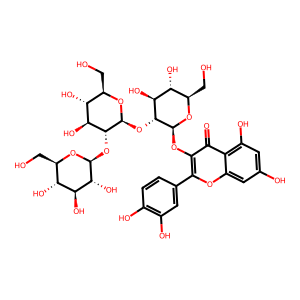

In [122]:
'''Búsqueda por nombre:

Nos van a solicitar el nombre de un producto natural, para posteriormente ejecutar un query simple a la API REST de LOTUS.
Este bloque nos va a devolver el status del query y la estrucutra química del compuesto que estamos buscando'''

compound=input("Introduce el nombre de un producto natural (en inglés):")
url=f"https://lotus.naturalproducts.net/api/search/simple?query={compound}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
df=pd.json_normalize(data,record_path=['naturalProducts'],meta=['originalQuery','determinedInputType'])
smiles=df.loc[0,'smiles']
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{compound}\"")
img


O, podemos emplear una búsqueda por SMILES de la estructura de la molécula
Por ejemplo, podemos buscar:
- Menthol, el compuesto responsable del aroma a menta de *Menta piperita* (menta): C[C@@H]1CC[C@H]([C@@H](C1)O)C(C)C
- Cocaine, un alcaloide de la planta de coca (*Erythroxylum coca*): COC(=O)[C@H]1[C@@H](OC(=O)c2ccccc2)C[C@@H]2CC[C@H]1N2C
- Geraniol, presente en las flores de geranio (*Geranium* sp.): CC(=CCC/C(=C/CO)/C)C
- Delphinidin, una antociandinina que da colores azules a flores como las dalias y las petunias: C1=C(C=C(C(=C1O)[O-])O)C2=C(C=C3C(=CC(=O)C=C3O2)O)O 

Status code del query: 200
Estructura química del query "CC1=C(C(=O)C=C2C1=CC=C3[C@]2(CC[C@@]4([C@@]3(CC[C@@]5([C@H]4C[C@](CC5)(C)C(=O)O)C)C)C)C)O "


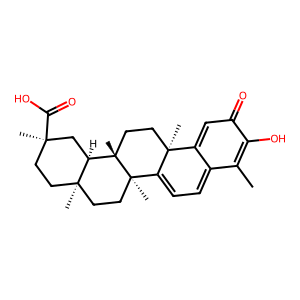

In [136]:
smiles=input("Introduce el SMILES de una molécula aquí")
url=f"https://lotus.naturalproducts.net/api/search/substructure?type=vf&max-hits=10&smiles={smiles}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{smiles}\"")
img



In [141]:
# Plot en 3D de la molécula query
from rdkit.Chem import AllChem, rdCoordGen
from rdkit.Chem.Draw import IPythonConsole 
IPythonConsole.ipython_useSVG=True
import py3Dmol

'''Armado, inserción de átomos de hidrógeno y optimización con MMFF94
La función recibe un objeto mol de RDKit, para posteriormente generar
coordenadas XYZ para cada átomo que constituye la molécula'''
def mol3d(mol):
    mol=Chem.MolFromSmiles(smiles)
    rdCoordGen.AddCoords(mol)
    mol=Chem.AddHs(mol,addCoords=True)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol
mol=mol3d(smiles)

view = py3Dmol.view(
    data=Chem.MolToMolBlock(mol),  # Convert the RDKit molecule for py3Dmol
    style={"stick": {}, "sphere": {"scale": 0.3}}
)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [137]:
# Organizando los datos en un dataframe de Pandas
df=pd.json_normalize(data['naturalProducts'])
df=df.dropna(axis=1,how='any')
df.drop(list(df.filter(regex="fragment*")),axis=1,inplace=True)
# Vamos a imprimir varias características de nuestra tabla
print("¿Cuántas filas y columnas tiene el archivo?","\n",df.shape[0],"columnas y", df.shape[1],"filas\n")
print("Esta es la descripción de la tabla:\n")
df=df.filter(['id','lotus_id','traditional_name','molecular_weight','contains_sugar','smiles'])
display(df)

¿Cuántas filas y columnas tiene el archivo? 
 8 columnas y 12 filas

Esta es la descripción de la tabla:



,lotus_id,traditional_name,molecular_weight,smiles
0,LTS0029200,celastrol,450.610709,CC1=C(O)C(=O)C=C2C1=CC=C1[C@@]3(C)CC[C@@]4(C)C...
1,LTS0073737,"methyl (2s,4as,6as,12br,14as,14br)-10-hydroxy-...",478.620850,COC(=O)[C@@]1(C)C[C@@H]2[C@@](C)(CC[C@]3(C)C4=...
2,LTS0049097,"methyl (2s,4as,6s,6as,12bs,14as,14br)-6,10-dih...",494.620255,COC(=O)[C@@]1(C)C[C@@H]2[C@](C)(CC1=O)C[C@H](O...
3,LTS0276086,celastrol methyl ester,464.637327,COC(=O)[C@]1(C)CC[C@]2(C)CC[C@]3(C)C4=CC=C5C(=...
4,LTS0213898,"methyl (2r,4ar,6s,6as,12bs,14as,14br)-6,10-dih...",480.636732,COC(=O)[C@]1(C)CC[C@]2(C)C[C@H](O)[C@]3(C)C4=C...
5,LTS0087077,"methyl (2r,4as,6as,12br,14as,14br)-10-hydroxy-...",480.636732,COC(=O)[C@]1(CO)CC[C@]2(C)CC[C@]3(C)C4=CC=C5C(...
6,LTS0212845,"methyl (2s,4r,4ar,6as,12br,14as,14bs)-4,10-dih...",480.636732,COC(=O)[C@@]1(C)C[C@H]2[C@]3(C)CC[C@@]4(C)C5=C...
7,LTS0082735,"methyl (2s,4r,4ar,6as,12br,14as,14bs)-4,10-dih...",494.663349,COC(=O)[C@@]1(C)C[C@H]2[C@]3(C)CC[C@@]4(C)C5=C...


Estructuras moleculares similares a nuestro query O=c1c(O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12
0                                            celastrol
1    methyl (2s,4as,6as,12br,14as,14br)-10-hydroxy-...
2    methyl (2s,4as,6s,6as,12bs,14as,14br)-6,10-dih...
3                               celastrol methyl ester
4    methyl (2r,4ar,6s,6as,12bs,14as,14br)-6,10-dih...
5    methyl (2r,4as,6as,12br,14as,14br)-10-hydroxy-...
6    methyl (2s,4r,4ar,6as,12br,14as,14bs)-4,10-dih...
7    methyl (2s,4r,4ar,6as,12br,14as,14bs)-4,10-dih...
Name: traditional_name, dtype: object


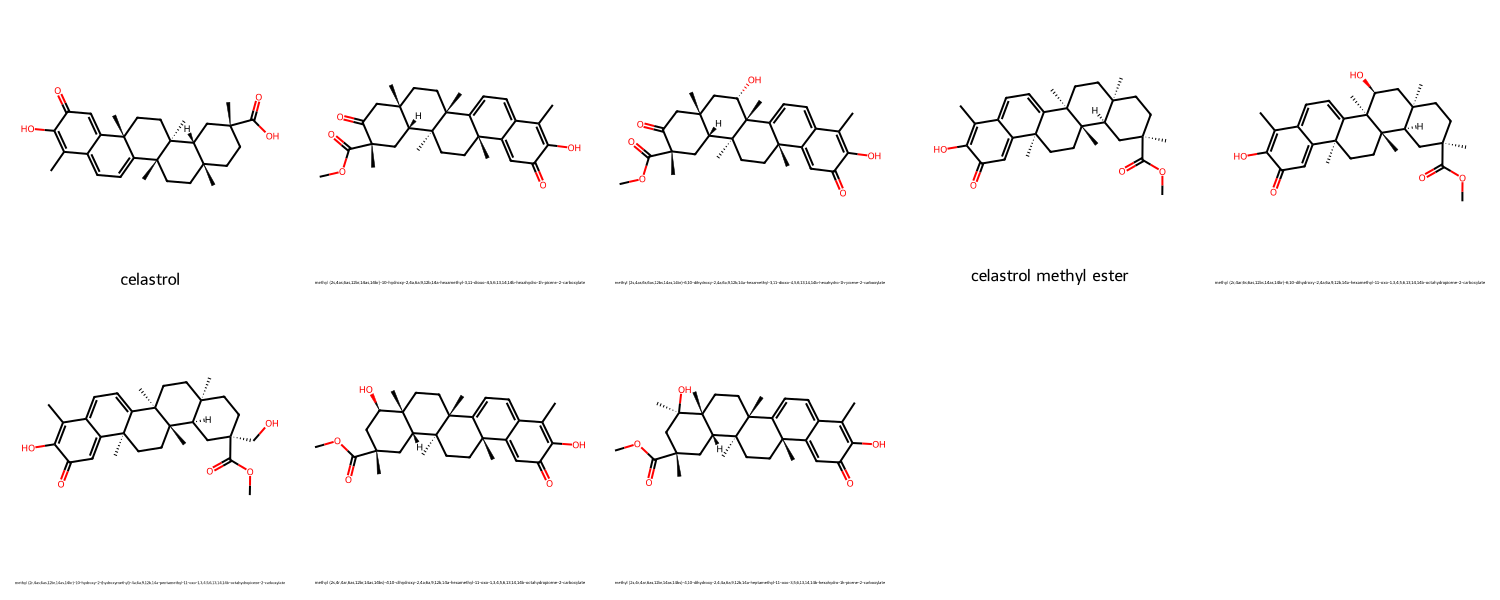

In [142]:
# Imágenes de estructuras similares al query:
mol =  [ Chem.MolFromSmiles(x) for x in df['smiles']]
names=list(df['traditional_name'])
img=Draw.MolsToGridImage(mol,molsPerRow=5,legends=names,subImgSize=(300,300))  
print(f"Estructuras moleculares similares a nuestro query {querySmiles}")
print(df['traditional_name'])
img